The data set being cleaned and explored is 2008 Olympic Medalists

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


olympics_raw = pd.read_csv("olympics_08_medalists.csv")

olympics = olympics_raw.copy()

# Display the first few rows
display(olympics.head())

,medalist_name,male_archery,female_archery,male_athletics,female_athletics,male_badminton,female_badminton,male_baseball,male_basketball,female_basketball,...,female_beach volleyball,male_volleyball,female_volleyball,male_water polo,female_water polo,male_weightlifting,female_weightlifting,male_freestyle wrestling,female_freestyle wrestling,male_greco-roman wrestling
0,Aaron Armstrong,NaN,NaN,gold,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Aaron Peirsol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Abdullo Tangriev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abeer Abdelrahman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,bronze,NaN,NaN,NaN
4,Abhinav,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Inspecting Initial Dataset - identifying dimensions, data types, and missing values

In [4]:
print("Dataset dimensions:", olympics.shape)

print("\nColumn names:")
print(olympics.columns.tolist())

print("\nData types:")
print(olympics.dtypes)

print("\nMissing values in the original dataset:",
      olympics.isna().sum().sum())

Dataset dimensions: (1875, 71)

Column names:
['medalist_name', 'male_archery', 'female_archery', 'male_athletics', 'female_athletics', 'male_badminton', 'female_badminton', 'male_baseball', 'male_basketball', 'female_basketball', 'male_boxing', 'male_canoeing and kayaking', 'female_canoeing and kayaking', 'male_road bicycle racing', 'female_road bicycle racing', 'male_track cycling', 'female_track cycling', 'male_mountain biking', 'female_mountain biking', 'male_bmx', 'female_bmx', 'male_diving', 'female_diving', 'female_equestrian sport', 'male_equestrian sport', 'male_fencing', 'female_fencing', 'male_field hockey', 'female_field hockey', 'male_association football', 'female_association football', 'male_artistic gymnastics', 'female_artistic gymnastics', 'female_rhythmic gymnastics', 'male_trampoline gymnastics', 'female_trampoline gymnastics', 'male_handball', 'female_handball', 'male_judo', 'female_judo', 'male_modern pentathlon', 'female_modern pentathlon', 'male_rowing', 'female

Reshaping Data - reshaped data using melt and splitting based on sport and gender. Also dropped athletes that did not win a medal or a medal is not recorded

In [5]:
medal_columns = [
    column for column in olympics.columns
    if column != "medalist_name"
]

olympics_long = olympics.melt(
    id_vars=["medalist_name"],
    value_vars=medal_columns,
    var_name="gender_sport",
    value_name="medal"
)

olympics_long = olympics_long.dropna(subset=["medal"]).copy()

display(olympics_long.head(10))


,medalist_name,gender_sport,medal
177,Bair Badënov,male_archery,bronze
676,Ilario Di Buò,male_archery,silver
682,Im Dong-hyun,male_archery,gold
760,Jiang Lin,male_archery,bronze
920,Lee Chang-hwan,male_archery,gold
950,Li Wenquan,male_archery,bronze
1043,Marco Galiazzo,male_archery,silver
1107,Mauro Nespoli,male_archery,silver
1314,Park Kyung-mo,male_archery,silver
1710,Viktor Ruban,male_archery,gold


Splitting and cleaning variables - split the gender_sport variable into two columns. Also change _ into spaces and got rid of dead space in variables (i.e instead of "Rowan ", "Rowan"). Made data points capitalized correctly too

In [6]:
olympics_long[["gender", "sport"]] = (
    olympics_long["gender_sport"].str.split("_", n=1, expand=True)
)

olympics_long["sport"] = (
    olympics_long["sport"]
    .str.replace("-", " ", regex=False)
    .str.strip()
    .str.title()
)

olympics_long["gender"] = olympics_long["gender"].str.title()
olympics_long["medal"] = olympics_long["medal"].str.strip().str.title()

olympics_long["medalist_name"] = (
    olympics_long["medalist_name"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

olympics_tidy = olympics_long[
    ["medalist_name", "gender", "sport", "medal"]
].copy()

display(olympics_tidy.head(10))

,medalist_name,gender,sport,medal
177,Bair Badënov,Male,Archery,Bronze
676,Ilario Di Buò,Male,Archery,Silver
682,Im Dong-hyun,Male,Archery,Gold
760,Jiang Lin,Male,Archery,Bronze
920,Lee Chang-hwan,Male,Archery,Gold
950,Li Wenquan,Male,Archery,Bronze
1043,Marco Galiazzo,Male,Archery,Silver
1107,Mauro Nespoli,Male,Archery,Silver
1314,Park Kyung-mo,Male,Archery,Silver
1710,Viktor Ruban,Male,Archery,Gold


Initial Table Creation - I separted observational units into different tables to be examined

In [7]:
athletes = (
    olympics_tidy[["medalist_name"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

medal_records = olympics_tidy.copy()

print("Athlete table:")
display(athletes.head())

print("Medal-record table:")
display(medal_records.head())

print("Unique athletes:", len(athletes))
print("Medal records:", len(medal_records))

Athlete table:


,medalist_name
0,Bair Badënov
1,Ilario Di Buò
2,Im Dong-hyun
3,Jiang Lin
4,Lee Chang-hwan


Medal-record table:


,medalist_name,gender,sport,medal
177,Bair Badënov,Male,Archery,Bronze
676,Ilario Di Buò,Male,Archery,Silver
682,Im Dong-hyun,Male,Archery,Gold
760,Jiang Lin,Male,Archery,Bronze
920,Lee Chang-hwan,Male,Archery,Gold


Unique athletes: 1875
Medal records: 1875


Validating Cleaned Data - I checked the tidy data set for missing values and examined new dimensions and data types. I also confirmed that each column represents a distinct variable

In [10]:
print("Missing values in tidy table:")
print(medal_records.isna().sum())

print("\nTidy table columns:", medal_records.columns.tolist())

Missing values in tidy table:
medalist_name    0
gender           0
sport            0
medal            0
dtype: int64

Tidy table columns: ['medalist_name', 'gender', 'sport', 'medal']


Visualization 1: Medal Distribution - This bar chart compares the number of recorded gold, silver, and bronze medals

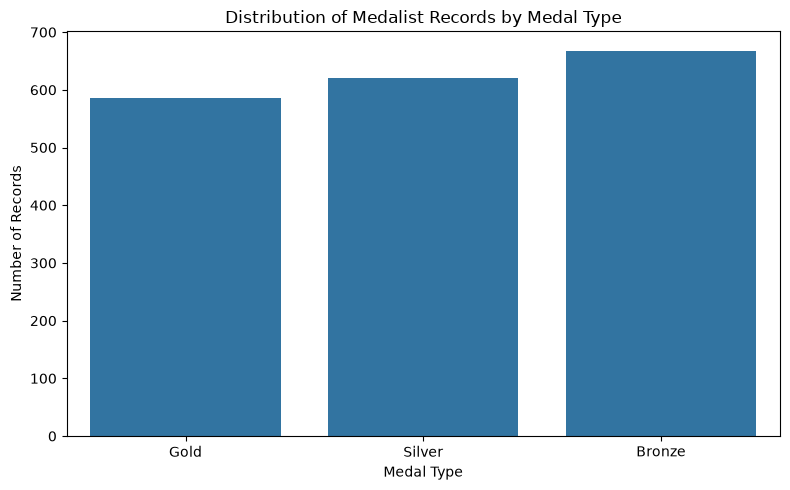

,Record Count
medal,
Gold,586
Silver,621
Bronze,668


In [11]:
medal_counts = (
    medal_records["medal"]
    .value_counts()
    .reindex(["Gold", "Silver", "Bronze"])
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=medal_counts.index,
    y=medal_counts.values
)

plt.title("Distribution of Medalist Records by Medal Type")
plt.xlabel("Medal Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

display(medal_counts.rename("Record Count").to_frame())

Visualization 2: Top Sports by Medalist Records - This horizontal bar chart displays the ten sports with the highest numbers of medalists

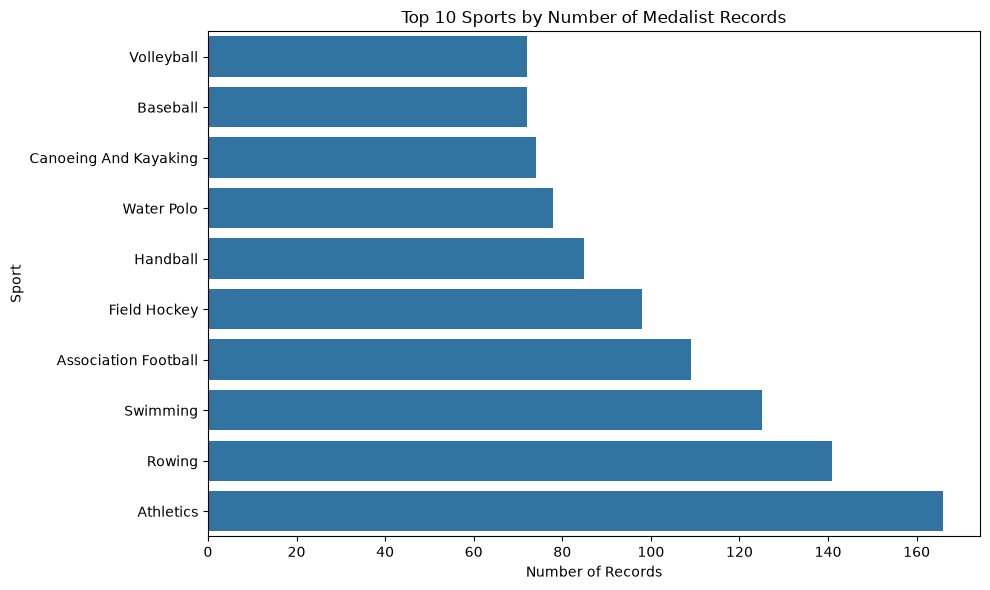

In [12]:
top_sports = (
    medal_records["sport"]
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_sports.values,
    y=top_sports.index
)

plt.title("Top 10 Sports by Number of Medalist Records")
plt.xlabel("Number of Records")
plt.ylabel("Sport")
plt.tight_layout()
plt.show()

Pivot Table: Medal Records by Sport and Medal Type - I used a pivot table to aggregate medalist records by sport and medal type

In [13]:
medal_pivot = pd.pivot_table(
    medal_records,
    index="sport",
    columns="medal",
    values="medalist_name",
    aggfunc="count",
    fill_value=0
)

medal_pivot = medal_pivot.reindex(
    columns=["Gold", "Silver", "Bronze"],
    fill_value=0
)

medal_pivot["Total Records"] = medal_pivot.sum(axis=1)

medal_pivot = medal_pivot.sort_values(
    "Total Records",
    ascending=False
)

display(medal_pivot.head(15))

medal,Gold,Silver,Bronze,Total Records
sport,,,,
Athletics,52,59,55,166
Rowing,48,48,45,141
Swimming,39,43,43,125
Association Football,37,36,36,109
Field Hockey,33,32,33,98
Handball,29,28,28,85
Water Polo,26,26,26,78
Canoeing And Kayaking,24,23,27,74
Volleyball,24,24,24,72
